# 02 — ICR gene clustering

Can we group samples with similar immune gene-expression profiles? We use 20 ICR genes across all 1,082 samples. Once the groups are formed, we compare them with the known molecular subtypes.

Notebook 01 prepares the expression matrix and annotations used here.


In [1]:
from scipy.stats import chi2_contingency
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from threadpoolctl import threadpool_limits
import seaborn as sns


## Loading the signature

We use the gene annotations prepared in notebook 01 to select the 20 ICR symbols and check for missing or infinite values.


In [ ]:
root = Path.cwd() if (Path.cwd() / 'data').exists() else Path.cwd().parent
x = pd.read_parquet(root / 'data/interim/expression_log2_rsem.parquet')
ann = pd.read_csv(root / 'data/interim/gene_annotations.csv')
genes = 'CCL5 CD274 CD8A CD8B CTLA4 CXCL9 CXCL10 FOXP3 GNLY GZMA GZMB GZMH IDO1 IFNG IL12B IRF1 PDCD1 PRF1 STAT1 TBX21'.split()
ids = [str(ann.loc[ann.Hugo_Symbol.eq(g), 'Entrez_Gene_Id'].iloc[0]) for g in genes]
X = x.loc[:, ids].copy()
X.columns = genes

## Standardization by gene

We center each gene and divide by its standard deviation across the 1,082 samples. This gives the genes comparable scales when we calculate distances.


In [3]:
Z = StandardScaler().fit_transform(X)
print('Campioni e geni:', X.shape)


Campioni e geni: (1082, 20)


## Comparing the number of groups

K-means groups samples according to their distance from the cluster centres. We try values of `k` from 2 to 8 and compare the silhouette scores and group sizes.

We also repeat the analysis on ten random subsets containing 80% of the samples. Each time, we standardize the genes again and refit K-means. The adjusted Rand index (ARI) tells us how similar the assignments are for the samples in common.


In [4]:
rng = np.random.default_rng(42)
subsets = [np.sort(rng.choice(len(X), size=int(.8*len(X)), replace=False)) for _ in range(10)]
models = {}
rows = []
for k in range(2, 9):
    with threadpool_limits(limits=1):
        model = KMeans(n_clusters=k, random_state=42, n_init=20).fit(Z)
    models[k] = model
    stability = []
    for j, ix in enumerate(subsets):
        zsub = StandardScaler().fit_transform(X.iloc[ix])
        with threadpool_limits(limits=1):
            sub = KMeans(n_clusters=k, random_state=42+j, n_init=20).fit_predict(zsub)
        stability.append(adjusted_rand_score(model.labels_[ix], sub))
    rows.append({'k': k, 'silhouette': silhouette_score(Z, model.labels_), 'inerzia': model.inertia_, 'ari_medio': np.mean(stability), 'ari_min': np.min(stability), 'cluster_min': np.bincount(model.labels_).min()})


## Comparison results

In our results, k=2 has the highest silhouette score (0.385). With k=3, the silhouette is 0.298 and mean stability is 0.975. We look more closely at k=3 to compare low, intermediate and high ICR profiles.


In [5]:
grid = pd.DataFrame(rows)
best_k = int(grid.loc[grid.silhouette.idxmax(), 'k'])
labels = models[best_k].labels_
display(grid.round(3))
print('k scelto per silhouette:', best_k, '| dimensioni:', np.bincount(labels))
grid.to_csv(root / 'data/interim/06_icr_kmeans_grid.csv', index=False)
pd.DataFrame({'SAMPLE_ID': X.index, 'cluster': labels+1}).to_csv(root / 'data/interim/06_icr_assignments.csv', index=False)

# Inerzia per k=1..8, necessaria al grafico del gomito delle slide.
with threadpool_limits(limits=1):
    inertia_one = KMeans(n_clusters=1, random_state=42, n_init=20).fit(Z).inertia_
elbow = pd.concat([pd.DataFrame([{'k': 1, 'inertia': inertia_one}]), grid[['k', 'inerzia']].rename(columns={'inerzia': 'inertia'})], ignore_index=True)
elbow.to_csv(root / 'data/interim/21_icr_elbow.csv', index=False)


k scelto per silhouette: 2 | dimensioni: [479 603]


,k,silhouette,inerzia,ari_medio,ari_min,cluster_min
0,2,0.385,10907.642,0.950,0.883,479
1,3,0.298,8030.779,0.975,0.939,245
2,4,0.223,7008.029,0.884,0.638,175
3,5,0.187,6396.440,0.950,0.834,141
4,6,0.175,6072.546,0.801,0.599,134
5,7,0.150,5797.779,0.810,0.533,81
6,8,0.138,5575.354,0.749,0.490,50


## K-means elbow

The curve shows within-cluster sum of squares for k=1–8. We use k=3 for a closer look at the profiles. The highest silhouette in this grid occurs at k=2.


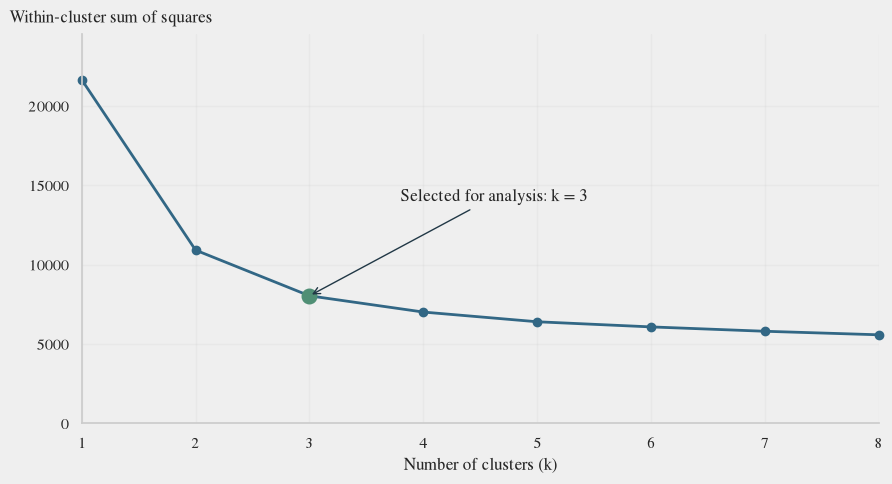

In [6]:
sns.set_theme(style='whitegrid',font_scale=1.0,rc={'font.family':'STIXGeneral','mathtext.fontset':'stix','figure.facecolor':'#efefef','axes.facecolor':'#efefef','savefig.facecolor':'#efefef','grid.alpha':.2})
plot_elbow = elbow.copy()
fig,ax=plt.subplots(figsize=(9,5)); ax.plot(plot_elbow.k,plot_elbow.inertia,'o-',color='#326785',lw=2,clip_on=False); k3=elbow.loc[elbow.k.eq(3),'inertia'].iloc[0]; ax.scatter([3],[k3],s=110,color='#508F75',zorder=3); ax.annotate('Selected for analysis: k = 3',xy=(3,k3),xytext=(3.8,14000),arrowprops={'arrowstyle':'->','color':'#213846'},fontsize=12); ax.set(xlabel='Number of clusters (k)',ylabel='',xticks=plot_elbow.k,xlim=(1,8),ylim=(0,24500)); ax.text(-.09,1.02,'Within-cluster sum of squares',transform=ax.transAxes,ha='left',va='bottom'); sns.despine(ax=ax); fig.tight_layout(); fig.savefig((root/'reports/figures')/'85_elbow_k3_selected.png',dpi=180); plt.show()

## Three relative profiles

We calculate the mean of the 20 standardized ICR genes for each sample. This gives us a simple way to describe the groups: C2 has the lowest mean, C1 is intermediate and C3 has the highest.


In [7]:
labels = models[3].labels_ + 1
score = pd.Series(Z.mean(axis=1), index=X.index, name='media_ICR_standardizzata')
profile = pd.DataFrame({'cluster': labels, 'score': score.to_numpy()}).groupby('cluster').score.agg(['size','mean','median','min','max'])
display(profile.round(3))
gene_means = pd.DataFrame(Z, columns=genes).assign(cluster=labels).groupby('cluster').mean()
display(gene_means.round(2))


,size,mean,median,min,max
cluster,,,,,
1,464,0.087,0.079,-0.440,0.662
2,373,-0.906,-0.834,-2.322,-0.379
3,245,1.214,1.143,0.662,2.468


,CCL5,CD274,CD8A,CD8B,CTLA4,CXCL9,CXCL10,FOXP3,GNLY,GZMA,GZMB,GZMH,IDO1,IFNG,IL12B,IRF1,PDCD1,PRF1,STAT1,TBX21
cluster,,,,,,,,,,,,,,,,,,,,
1,0.17,-0.05,0.15,0.15,0.11,0.12,0.08,0.09,0.13,0.20,0.08,0.16,0.06,-0.13,0.08,0.01,0.11,0.12,-0.03,0.13
2,-1.04,-0.63,-0.98,-0.92,-0.96,-0.96,-0.87,-0.89,-0.94,-1.03,-0.96,-0.95,-0.90,-0.79,-0.86,-0.82,-0.97,-1.00,-0.66,-1.01
3,1.25,1.06,1.21,1.11,1.25,1.24,1.17,1.18,1.19,1.19,1.32,1.14,1.26,1.44,1.15,1.23,1.27,1.30,1.05,1.30


## Comparing k=2 and k=3

The table shows how the three-group solution maps to the two-group solution. Cluster numbers are arbitrary labels and do not automatically identify the same group across fits.


In [8]:
cross = pd.crosstab(pd.Series(labels, name='k=3'), pd.Series(models[2].labels_+1, name='k=2'))
display(cross)
pd.DataFrame({'SAMPLE_ID': X.index, 'cluster_k3': labels, 'cluster_k2': models[2].labels_+1, 'media_icr_standardizzata': score.to_numpy()}).to_csv(root/'data/interim/07_icr_k3_assignments.csv', index=False)
profile.to_csv(root/'data/interim/07_icr_k3_profiles.csv')
cross.to_csv(root/'data/interim/07_icr_k2_k3_cross.csv')

k=2,1,2
k=3,,
1,234,230
2,0,373
3,245,0


## UMAP projection

We use UMAP to show the samples on a two-dimensional map. The K-means groups were calculated using all 20 standardized genes. The map uses 15 neighbours, `min_dist=0` and seed 42.


In [9]:
import umap
import warnings
from sklearn.manifold import trustworthiness
with threadpool_limits(limits=1), warnings.catch_warnings():
    warnings.filterwarnings("ignore", message="n_jobs value.*")
    coords = umap.UMAP(n_neighbors=15, min_dist=0.0, metric="euclidean", random_state=42, n_jobs=1).fit_transform(Z)
print("Trustworthiness a 15 vicini:", round(trustworthiness(Z, coords, n_neighbors=15), 4))

pd.DataFrame({'SAMPLE_ID': X.index, 'UMAP1': coords[:, 0], 'UMAP2': coords[:, 1], 'cluster': labels}).to_csv(root / 'data/interim/16_umap_best_coordinates.csv', index=False)


Trustworthiness a 15 vicini: 0.9475


### Displaying the assignments

The colours show the K-means groups. The shape of the map and the distances between distant points depend on the UMAP settings.


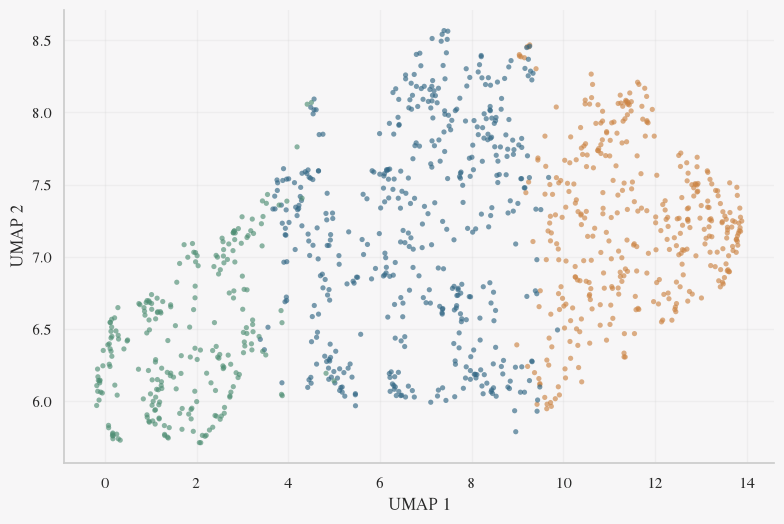

In [10]:
plt.rcParams.update({'figure.facecolor':'#f7f6f7','axes.facecolor':'#f7f6f7','savefig.facecolor':'#f7f6f7'})
coords_df=pd.DataFrame({'UMAP1':coords[:,0], 'UMAP2':coords[:,1], 'cluster':labels})
colors={1:'#326785',2:'#CC8545',3:'#508F75'}; descriptions={1:'intermediate',2:'low',3:'high'}
fig,ax=plt.subplots(figsize=(8,5.4))
for k in [2,1,3]:
    part=coords_df.loc[coords_df.cluster.eq(k)]
    ax.scatter(part.UMAP1,part.UMAP2,s=14,alpha=.65,color=colors[k],edgecolors='none',label=f'G{k}: {descriptions[k]}')
ax.set(xlabel='UMAP 1',ylabel='UMAP 2'); sns.despine(ax=ax)
fig.tight_layout(); fig.savefig((root/'reports/figures')/'72_en_umap.png',dpi=180); plt.show()


## Mean profiles of the 20 ICR genes

The two panels show the mean standardized expression of each of the 20 genes in the three clusters. Each value is a group mean; this plot does not show individual outliers.


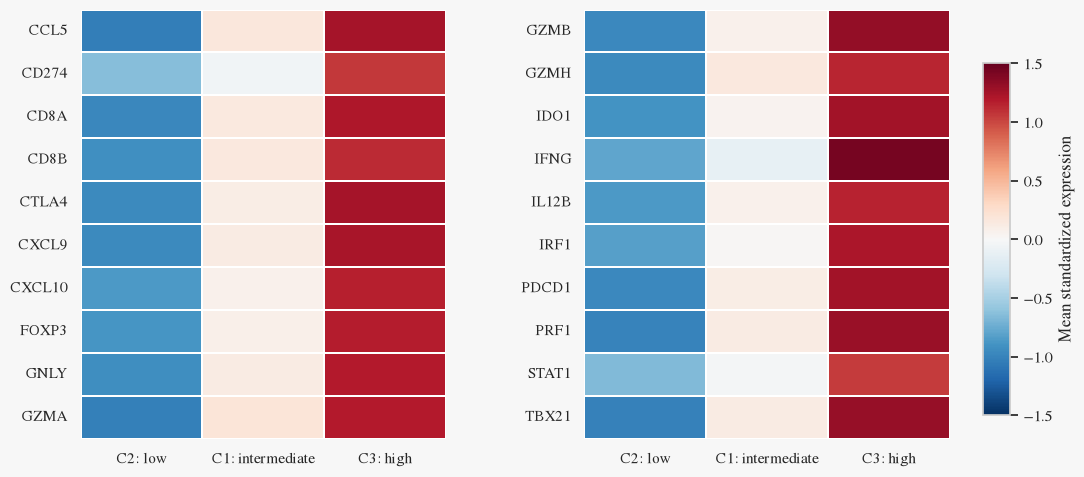

In [11]:
# Mean standardized expression for each gene in the three groups.
z = pd.DataFrame(Z, index=X.index, columns=genes)
means = z.assign(cluster=labels).groupby('cluster').mean().loc[[2,1,3]].T
means.columns = ['C2: low', 'C1: intermediate', 'C3: high']
plt.rcParams.update({'figure.facecolor':'#f7f7f7','axes.facecolor':'#f7f7f7','savefig.facecolor':'#f7f7f7'})
fig = plt.figure(figsize=(11,5.5))
axes = [fig.add_axes([.09,.158,.332,.78]), fig.add_axes([.548,.158,.332,.78])]
cax = fig.add_axes([.91,.20,.025,.64])
for ax, part in zip(axes, [means.iloc[:10], means.iloc[10:]]):
    sns.heatmap(part, ax=ax, cmap='RdBu_r', center=0, vmin=-1.5, vmax=1.5, linewidths=.25, linecolor='white', cbar=False)
    ax.tick_params(axis='x', rotation=0); ax.tick_params(axis='y', rotation=0)
    ax.set(xlabel='', ylabel='')
colorbar = fig.colorbar(axes[1].collections[0], cax=cax, ticks=[-1.5,-1,-.5,0,.5,1,1.5])
colorbar.set_label('Mean standardized expression')
fig.savefig(root/'reports/figures/73_en_icr_heatmap.png', dpi=180)
plt.show()


## Association with subtypes

We compare the groups with the known subtypes after clustering. The 101 samples without subtype labels are included in the clustering but not in the subtype comparison.

In our results, 43.9% of Basal samples and 13.0% of Luminal A samples are in the high ICR group. Each group contains more than one subtype.


In [12]:
clinical = pd.read_parquet(root/'data/interim/clinical_aligned.parquet').reindex(X.index)
counts = pd.crosstab(pd.Series(labels, index=X.index, name='Cluster'), clinical.SUBTYPE.fillna('Non disponibile').rename('Sottotipo'))
known = counts.drop(columns=['Non disponibile'])
by_cluster = known.div(known.sum(axis=1), axis=0)*100
by_subtype = known.div(known.sum(axis=0), axis=1)*100
print('Conteggi noti:\n', known.to_string())
print('\nPercentuali per cluster, sui soli sottotipi noti:\n', by_cluster.round(1).to_string())
print('\nPercentuali per sottotipo:\n', by_subtype.round(1).to_string())


Conteggi noti:
 Sottotipo  BRCA_Basal  BRCA_Her2  BRCA_LumA  BRCA_LumB  BRCA_Normal
Cluster                                                            
1                  59         27        236         81           18
2                  37         16        198         77            6
3                  75         35         65         39           12

Percentuali per cluster, sui soli sottotipi noti:
 Sottotipo  BRCA_Basal  BRCA_Her2  BRCA_LumA  BRCA_LumB  BRCA_Normal
Cluster                                                            
1                14.0        6.4       56.1       19.2          4.3
2                11.1        4.8       59.3       23.1          1.8
3                33.2       15.5       28.8       17.3          5.3

Percentuali per sottotipo:
 Sottotipo  BRCA_Basal  BRCA_Her2  BRCA_LumA  BRCA_LumB  BRCA_Normal
Cluster                                                            
1                34.5       34.6       47.3       41.1         50.0
2                21

## Association test

The chi-square test assesses the overall association between the two classifications. Cramér’s V summarizes its strength. In this dataset, χ²(8)=100.70 and V=0.227. The comparison does not account for other factors that may affect the association.


In [13]:
chi2, p, dof, expected = chi2_contingency(known)
n = known.to_numpy().sum()
v = np.sqrt(chi2/(n*min(known.shape[0]-1,known.shape[1]-1)))
print(f'\nChi-quadrato={chi2:.2f}, gradi di libertà={dof}, p={p:.3g}, V di Cramer={v:.3f}, frequenza attesa minima={expected.min():.2f}')
print('Campioni con sottotipo noto:',n,'; senza:',counts['Non disponibile'].sum())
by_subtype.to_csv(root/'data/interim/08_icr_k3_subtype_percent.csv')



Chi-quadrato=100.70, gradi di libertà=8, p=3.07e-18, V di Cramer=0.227, frequenza attesa minima=8.29
Campioni con sottotipo noto: 981 ; senza: 101


## Cluster composition by subtype

Each bar shows the share of low, intermediate and high ICR assignments within one subtype. The first bar summarizes all 1,082 samples, including those without subtype labels. Cluster and subtype labels do not coincide.


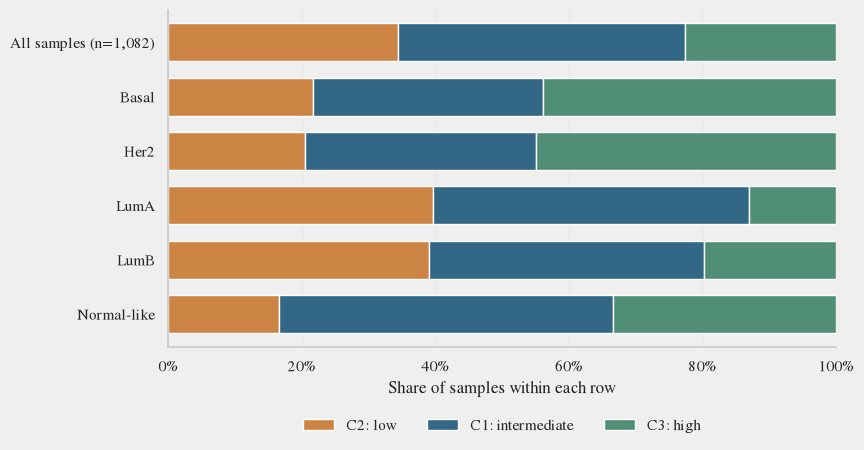

In [14]:
plt.rcParams.update({'figure.facecolor':'#efefef','axes.facecolor':'#efefef','savefig.facecolor':'#efefef'})
order=['BRCA_Basal','BRCA_Her2','BRCA_LumA','BRCA_LumB','BRCA_Normal']
all_samples=pd.Series(labels).value_counts().reindex([2,1,3],fill_value=0)/len(labels)*100
percent=by_subtype.loc[[2,1,3],order].T.copy()
percent.loc['All samples']=all_samples.to_numpy()
percent=percent.loc[['All samples']+order]
percent.columns=['C2: low','C1: intermediate','C3: high']
percent.index=['All samples (n=1,082)','Basal','Her2','LumA','LumB','Normal-like']
ax=percent.plot.barh(stacked=True,color=['#CC8545','#326785','#508F75'],figsize=(8.8,4.75),width=.7,edgecolor='white')
ax.invert_yaxis(); ax.set(xlabel='Share of samples within each row',ylabel='',xlim=(0,100)); ax.set_xticks([0,20,40,60,80,100],labels=['0%','20%','40%','60%','80%','100%'])
ax.grid(axis='y',visible=False); ax.legend(ncol=3,loc='lower center',bbox_to_anchor=(.5,-.30),frameon=False); sns.despine(ax=ax)
plt.tight_layout(); plt.savefig((root/'reports/figures')/'75_en_icr_subtypes.png',dpi=180); plt.show()
